1000
700
  account_number  account_type                       date operation  amount  \
0       ACC-1000  bank_account 2026-10-19 15:15:55.392942   deposit     200   
1       ACC-1000  bank_account 2026-10-19 15:15:56.394826   deposit     500   
2       ACC-1000  bank_account 2026-10-19 15:15:57.395962  withdraw     100   
3       ACC-1000  bank_account 2026-10-19 15:15:58.396924  withdraw     900   

   balance_after   status uid  
0           1200  success      
1           1700  success      
2           1600  success      
3            700  success      
Некорректная операция
  account_number  account_type                       date operation  amount  \
0       ACC-1000  bank_account 2026-10-19 15:15:55.392942   deposit     200   
1       ACC-1000  bank_account 2026-10-19 15:15:56.394826   deposit     500   
2       ACC-1000  bank_account 2026-10-19 15:15:57.395962  withdraw     100   
3       ACC-1000  bank_account 2026-10-19 15:15:58.396924  withdraw     900   
4       ACC-1000  

Text(0.5, 1.0, 'График изменения баланса')

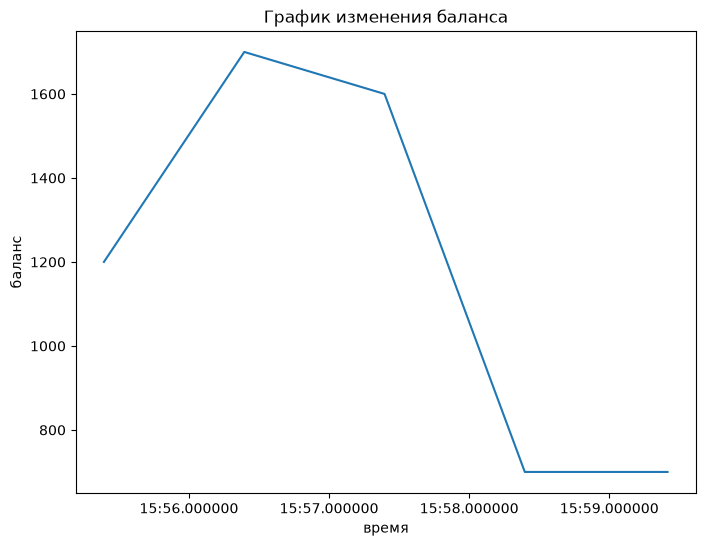

In [48]:
from datetime import datetime
import re
import csv
import json
import matplotlib.pyplot as plt
import pandas as pd
import time
import uuid


class BankAccount:
    account_number = 1000

    def __init__(self, name: str, balance: float):

        if balance < 0:
            raise ValueError("Баланс должен быть больше 0")

        if not re.fullmatch(r"[А-ЯЁA-Z][а-яёa-z]+ [А-ЯЁA-Z][а-яёa-z]+", name):
            raise ValueError("Некорректное имя")

        self.balance = balance
        self.name = name
        self.account_number = f"ACC-{BankAccount.account_number}"
        self.account_type = "bank_account"
        BankAccount.account_number += 1
        self.history = list()

    def createHistory(self, operation: str, summa: float, status: bool, uid: str = ""):

        self.history.append(
            {
                "account_number": self.account_number,
                "account_type": self.account_type,
                "date": datetime.now(),
                "operation": operation,
                "amount": summa,
                "balance_after": self.balance,
                "status": "success" if status else "fail",
                "uid": uid,
            }
        )

    def showBalance(self):
        return self.balance

    def showHistory(self):
        return pd.DataFrame(self.history)

    def deposit(self, amount: float, uid: str = ""):
        op = "deposit"

        if amount <= 0:
            self.createHistory(operation=op, status=False, summa=amount, uid=uid)
            raise ValueError("Сумма операции должна быть положительной")

        self.balance += amount
        self.createHistory(operation=op, status=True, summa=amount, uid=uid)

    def withdraw(self, amount: float, uid: str = ""):
        op = "withdraw"
        if amount <= 0:
            self.createHistory(operation=op, status=False, summa=amount, uid=uid)
            raise ValueError("Сумма операции должна быть положительной")

        if self.balance < amount:
            self.createHistory(operation=op, status=False, summa=amount, uid=uid)
            return False
        else:
            self.balance -= amount
            self.createHistory(operation=op, status=True, summa=amount, uid=uid)
            return True

    def getTopNOperations(self, n: int, min_amount: float):
        result = [
            record
            for record in self.history
            if record["status"] == "success" and record["amount"] >= min_amount
        ][-n:]

        return result

    def transfer(self, other, amount: float):
        uid = uuid.uuid4()
        if self.withdraw(amount, uid):
            other.deposit(amount, uid)

    def _parse_row(self, row):
        if self.account_type == "savings":
            allowed = {"deposit", "withdraw", "interest"}
        else:
            allowed = {"deposit", "withdraw"}

        if row["status"] not in ["fail", "success"]:
            return None

        try:
            amount = float(row["amount"])
            datetime.fromisoformat(row["date"])
        except (ValueError, KeyError, TypeError):
            return None

        if amount <= 0:
            return None

        if row["operation"] not in allowed:
            return None
        return row

    def _save_row(self, row):

        # record = dict()
        record = {
            "account_number": row["account_number"],
            "operation": row["operation"],
            "account_type": row["account_type"],
            "amount": float(row["amount"]),
            "date": datetime.fromisoformat(row["date"]),
            "balance_after": float(row["balance_after"]),
            "status": row["status"],
            "uid": "",
        }
        self.history.append(record)
        self.balance = float(row["balance_after"])

    def _load_from_csv(self, fpath: str):
        with open(fpath, "r", newline="") as file:
            rd = csv.DictReader(file)
            rows = list(rd)
            valid_rows = [
                row
                for row in rows
                if row["account_number"] == self.account_number
                and self._parse_row(row) is not None
            ]

            for row in valid_rows:
                self._save_row(row)

            return valid_rows

    def _load_from_json(self, fpath: str):
        with open(fpath, "r", encoding="utf-8") as file:
            a = json.load(file)
            valid_rows = [
                row
                for row in a
                if row["account_number"] == self.account_number
                and self._parse_row(row) is not None
            ]
            for row in valid_rows:
                self._save_row(row)

            # print(valid_rows)
            return valid_rows


# поставил слип для нормального отображения графика
alex = BankAccount("Alex Test", 1000)
print(alex.showBalance())
alex.deposit(200)
time.sleep(1)
alex.deposit(500)
time.sleep(1)
alex.withdraw(100)
time.sleep(1)
alex.withdraw(900)
time.sleep(1)
print(alex.showBalance())
print(alex.showHistory())
try:
    alex.withdraw(-10000)
except ValueError:
    print("Некорректная операция")

df = alex.showHistory()
print(df)
# график
fig, ax = plt.subplots(figsize=(8, 6))

plt.plot(df["date"], df["balance_after"])
ax.set_xlabel("время")
ax.set_ylabel("баланс")
ax.set_title("График изменения баланса")

In [47]:
# расчетный
class CheckingAccount(BankAccount):

    def __init__(self, name: str, balance: float):
        super().__init__(name, balance)
        self.account_type = "checking"


# сберегательный счет
class SavingsAccount(BankAccount):
    def __init__(self, name: str, balance: float):
        super().__init__(name, balance)
        self.account_type = "savings"

    def new_percent(self, perc: float):
        op = "interest"
        if perc <= 0:
            self.createHistory(summa=0, operation=op, status=False)
            raise ValueError("Некорректный процент")

        amount = self.balance * (perc / 100)
        self.balance += amount
        self.createHistory(summa=amount, operation=op, status=True)

    def withdraw(self, amount: float, uid: str = ""):
        op = "withdraw"
        if (0.5 * self.balance) < amount:

            self.createHistory(summa=amount, operation=op, status=False, uid=uid)
            return False

        else:
            return super().withdraw(amount, uid=uid)


man1 = SavingsAccount("Steve Bro", 2000)
# print(man1.showBalance())

man2 = CheckingAccount("Luis Que", 500)
print(f"{man1.name} oldbalance", man1.showBalance())
print(f"{man2.name} old balance", man2.showBalance())
transfer_sum = 200
man2.transfer(man1, transfer_sum)
print(f"TRANSFER", transfer_sum)
print(f"{man1.name} new balance", man1.showBalance())
print(f"{man2.name} new balance", man2.showBalance())
print(man2.showHistory())

Steve Bro oldbalance 2000
Luis Que old balance 500
TRANSFER 200
Steve Bro new balance 2200
Luis Que new balance 300


  account_number account_type                       date operation  amount  \
0       ACC-1012     checking 2026-10-19 15:15:44.658565  withdraw     200   

   balance_after   status                                   uid  
0            300  success  f9754c6d-f665-41c8-a1ba-6299de954f56  


In [46]:
bb_csv = BankAccount("Morgan Fest", 0)
bb_csv.account_number = "ACC-100001"
bb_csv._load_from_csv("transactions_dirty.csv")
print(bb_csv.showBalance())

print(bb_csv.showHistory()[:3])
bb_json = BankAccount("Morgan Kest", 0)

bb_json.account_number = "ACC-100003"
bb_json._load_from_json("transactions_dirty.json")
print(bb_json.showBalance())
print(bb_json.showHistory()[:3])

7431.0
  account_number operation account_type  amount                date  \
0     ACC-100001   deposit     checking   921.0 2025-09-27 22:17:26   
1     ACC-100001   deposit     checking   607.0 2025-09-27 22:17:26   
2     ACC-100001   deposit     checking   488.0 2025-09-28 22:17:26   

   balance_after   status uid  
0         2121.0  success      
1         2728.0  success      
2         3216.0  success      
4634.0
  account_number operation account_type  amount                date  \
0     ACC-100003   deposit     checking   233.0 2025-10-02 22:17:26   
1     ACC-100003   deposit     checking   720.0 2025-10-05 22:17:26   
2     ACC-100003   deposit     checking   296.0 2025-10-06 22:17:26   

   balance_after   status uid  
0         1033.0  success      
1         1461.0  success      
2         1467.0  success      
